# 02 - Burnt area mapping + a Random Forest classifier

**Author:** mrseabag ([github.com/mrseabag](https://github.com/mrseabag))

This follows on from `01_satellite_basics.ipynb`. In that one I could load Sentinel-2 bands and show them, but I never got as far as working out what actually burnt.

The burnt area part follows the Digital Earth Australia (DEA) notebook
[Burnt area mapping using Sentinel-2 data](https://knowledge.dea.ga.gov.au/notebooks/Real_world_examples/Burnt_area_mapping/).
I used the same fire (part of the Clyde Mountain fire, north of Batemans Bay NSW, Black Summer, 5 Jan 2020), the same date windows and the same dNBR threshold, so I can check my numbers against theirs.

What I changed / added:

1. **No DEA Sandbox needed.** The DEA notebook uses `datacube` + `load_ard`, which only really works on the Sandbox/NCI. DEA also publishes the same Sentinel-2 ARD on a public STAC catalogue (`explorer.dea.ga.gov.au/stac`), so I load it with `pystac-client` + `odc-stac` and do the Fmask cloud filtering myself. That means it runs on a normal laptop.
2. **A Random Forest classifier** (scikit-learn) trained on the pixels where dNBR is confident, then used on everything else. I train two versions:
   - **Model A**: pre-fire + post-fire bands and indices (has dNBR in it, so it's mostly a sanity check)
   - **Model B**: post-fire bands only. This is the interesting one, because it asks if you can map a burn from one post-fire image when there's no clean before image.
3. **A spatial train/test split.** Neighbouring pixels are almost identical, so a random pixel split gives fake 99.9% accuracy. I split by 1 km blocks instead.
4. **A transfer test on a Queensland fire** (Binna Burra / Sarabah, Sept 2019), which the models never saw in training.

Background: my earlier project ([fire-detection-neural-nets](https://github.com/mrseabag/fire-detection-neural-nets)) compared YOLOv7 and Detectron2 for spotting active fire/smoke in camera images. That's detection *during* a fire. This notebook is the other half, mapping what's left *after* a fire from space.

> Credit: the method, case study and thresholds come from the DEA notebook above (Geoscience Australia, Apache 2.0 code licence, CC BY 4.0 data). The data is Geoscience Australia Sentinel-2 ARD Collection 3. Any mistakes in my changes are mine.

## Setup

```
pip install pystac-client odc-stac "dask[array]" rioxarray scikit-learn matplotlib numpy pandas
```

The data sits in the `dea-public-data` S3 bucket, which is public, so no AWS account is needed. You just have to tell GDAL not to sign requests.

In [1]:
import os

# dea-public-data is a public bucket, so no AWS keys are needed, but GDAL has to be told to skip signing
os.environ["AWS_NO_SIGN_REQUEST"] = "YES"
os.environ["AWS_DEFAULT_REGION"] = "ap-southeast-2"
# stops GDAL listing the whole S3 folder every time it opens a file (way faster)
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray  # not called directly, but it adds the .rio accessor used for the GeoTIFF export
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import pystac_client
import odc.stac
import rasterio

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, cohen_kappa_score)
from sklearn.inspection import permutation_importance

import warnings
# rasterio complains about "no geotransform" while odc-stac reprojects - harmless, just noisy
warnings.filterwarnings("ignore", category=rasterio.errors.NotGeoreferencedWarning)

plt.rcParams["figure.dpi"] = 80  # keeps the notebook file size down on GitHub

# fixed seed so the RF results come out the same each run
RNG_SEED = 42

## Study area and dates

These are the same values as the DEA notebook. The baseline is 3 months before the fire and the post-fire window is 3 months after.

In [2]:
# Clyde Mountain fire, north of Batemans Bay NSW (same point as the DEA notebook)
lat, lon = -35.653031, 150.231667
buffer = 0.07

# odc-stac/pystac want [west, south, east, north]
# (in notebook 01 I accidentally overwrote my real bbox with random ints 1-200, which isn't lat/lon at all, so it's fixed here)
bbox = [lon - buffer, lat - buffer, lon + buffer, lat + buffer]

fire_date = "2020-01-05"
baseline_window = "2019-10-06/2020-01-04"   # 3 months before
postfire_window = "2020-01-06/2020-04-04"   # 3 months after

print("bbox:", [round(v, 4) for v in bbox])

bbox: [150.1617, -35.723, 150.3017, -35.583]


## Connecting to the DEA STAC catalogue

`ga_s2am_ard_3` and `ga_s2bm_ard_3` are Sentinel-2A and 2B. (DEA also has 2C in `ga_s2cm_ard_3`, but that only launched in 2024 so it's no use for a 2020 fire.)

The bands are NBART surface reflectance, i.e. corrected for terrain and the atmosphere, so I don't have to do that myself. It's the same data `load_ard` gives you on the Sandbox.

In [3]:
catalog = pystac_client.Client.open("https://explorer.dea.ga.gov.au/stac")

COLLECTIONS = ["ga_s2am_ard_3", "ga_s2bm_ard_3", "ga_s2cm_ard_3"]

# blue/green/red/nir for pictures and NDVI, both SWIRs for NBR and NBR2
# oa_fmask is the cloud mask that comes with the ARD
BANDS = ["nbart_blue", "nbart_green", "nbart_red", "nbart_nir_1",
         "nbart_swir_2", "nbart_swir_3", "oa_fmask"]

# Fmask classes: 0 nodata, 1 valid, 2 cloud, 3 shadow, 4 snow, 5 water
# keeping valid/snow/water is the same default load_ard uses
GOOD_FMASK = [1, 4, 5]

### My version of `load_ard`

On the Sandbox, `load_ard(..., min_gooddata=0.8)` throws out any date that's less than 80% clear, then masks the cloudy pixels in the dates it keeps. This function does the same thing with odc-stac:

1. search the catalogue
2. load everything onto one 20 m grid in EPSG:3577 (Australian Albers, same as DEA)
3. work out the clear fraction of each date from Fmask and drop the bad dates
4. set the leftover cloud/shadow pixels to NaN and scale reflectance to 0-1

In [4]:
def load_s2_ard(bbox, time_range, min_gooddata=0.8, resolution=20):
    items = list(catalog.search(collections=COLLECTIONS, bbox=bbox,
                                datetime=time_range).items())
    if len(items) == 0:
        raise ValueError(f"No Sentinel-2 scenes found for {time_range}")

    ds = odc.stac.load(
        items,
        bands=BANDS,
        bbox=bbox,
        crs="EPSG:3577",
        resolution=resolution,
        groupby="solar_day",        # joins tiles from the same pass into one image
        chunks={"x": 2048, "y": 2048},
    )

    # work out how clear each date is (ignoring nodata pixels at the swath edges)
    fmask = ds.oa_fmask.compute()
    good = fmask.isin(GOOD_FMASK)
    has_data = fmask != 0
    good_frac = good.sum(["x", "y"]) / has_data.sum(["x", "y"])

    keep = (good_frac >= min_gooddata).values
    print(f"{time_range}: {len(ds.time)} time steps found, keeping {keep.sum()} with >= {min_gooddata:.0%} good data")

    ds = ds.isel(time=keep)
    good = good.isel(time=keep)

    # DEA stores reflectance as int16 x 10000 with -999 as nodata
    refl = ds.drop_vars("oa_fmask")
    refl = refl.where((refl != -999) & good) / 10000.0
    return refl.compute()


baseline = load_s2_ard(bbox, baseline_window)
postfire = load_s2_ard(bbox, postfire_window)

2019-10-06/2020-01-04: 17 time steps found, keeping 8 with >= 80% good data


2020-01-06/2020-04-04: 18 time steps found, keeping 8 with >= 80% good data


The DEA notebook kept **8 of 17** baseline and **8 of 18** post-fire time steps. If my numbers match that, my Fmask filter is doing the same job as `load_ard`.

## Indices

**NBR (Normalised Burn Ratio)** = (NIR - SWIR) / (NIR + SWIR), using Band 8 (NIR) and Band 12 (SWIR 2.2 µm, which DEA calls `nbart_swir_3`).
Healthy vegetation reflects a lot of NIR and little SWIR. Burnt ground is the reverse, so NBR drops after a fire.

**dNBR** = baseline NBR - post-fire NBR. Big positive values mean it burnt.

I've also added NDVI and NBR2 (both SWIR bands), since they'll be extra features for the Random Forest.

In [5]:
def add_indices(ds):
    ds = ds.copy()
    ds["NBR"] = (ds.nbart_nir_1 - ds.nbart_swir_3) / (ds.nbart_nir_1 + ds.nbart_swir_3)
    ds["NDVI"] = (ds.nbart_nir_1 - ds.nbart_red) / (ds.nbart_nir_1 + ds.nbart_red)
    # NBR2 tends to pick up char/moisture changes the normal NBR misses
    ds["NBR2"] = (ds.nbart_swir_2 - ds.nbart_swir_3) / (ds.nbart_swir_2 + ds.nbart_swir_3)
    return ds


# median composites like the DEA notebook - the median gets rid of most leftover cloud and smoke
baseline_med = add_indices(baseline.median("time"))
post_med = add_indices(postfire.median("time"))

delta_NBR = baseline_med.NBR - post_med.NBR

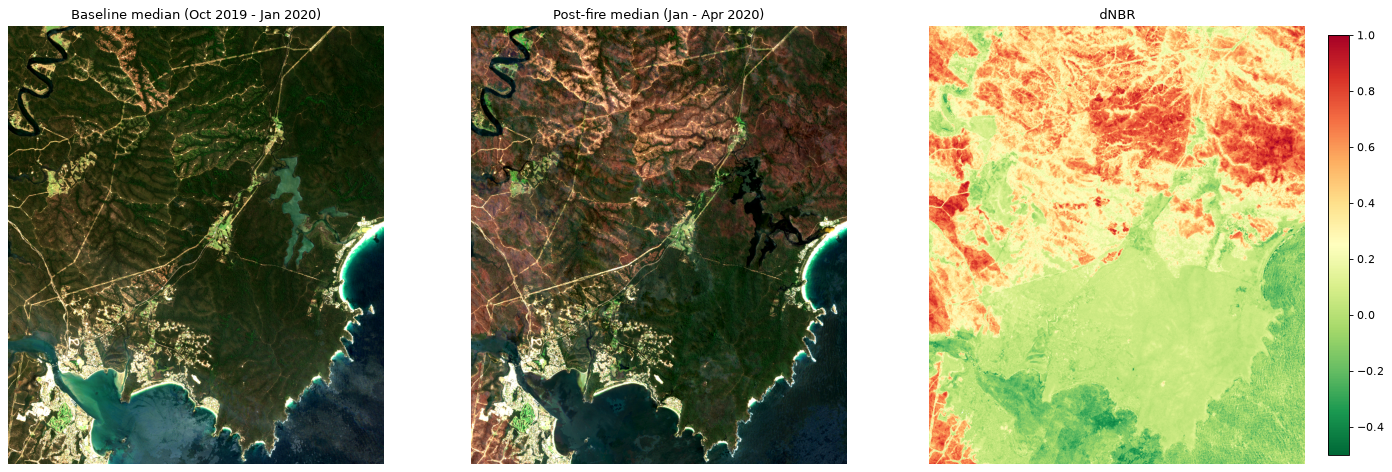

In [6]:
def rgb_array(ds, low=2, high=98):
    # 2-98% percentile stretch (same stretch_band idea as notebook 01)
    stack = np.dstack([ds.nbart_red.values, ds.nbart_green.values, ds.nbart_blue.values])
    lo, hi = np.nanpercentile(stack, low), np.nanpercentile(stack, high)
    return np.clip((stack - lo) / (hi - lo), 0, 1)


fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(rgb_array(baseline_med)); axes[0].set_title("Baseline median (Oct 2019 - Jan 2020)")
axes[1].imshow(rgb_array(post_med)); axes[1].set_title("Post-fire median (Jan - Apr 2020)")
im = axes[2].imshow(delta_NBR, cmap="RdYlGn_r", vmin=-0.5, vmax=1.0)
axes[2].set_title("dNBR")
plt.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Threshold method (the DEA baseline)

The DEA notebook uses **dNBR > 0.3**. The paper they cite (Rahman et al. 2018) suggests 0.1 for Sentinel-2, but that gave false positives in this forest because the vegetation was already drying out before the fire, so they raised it.

In [7]:
threshold = 0.3
burnt_threshold = delta_NBR > threshold
valid = delta_NBR.notnull()

# 20 m pixels -> 400 m^2 = 0.0004 km^2
pixel_km2 = (20 * 20) / 1e6


def area_km2(mask):
    return float(mask.sum()) * pixel_km2


print(f"Burnt   (threshold): {area_km2(burnt_threshold & valid):.2f} km2")
print(f"Unburnt (threshold): {area_km2(~burnt_threshold & valid):.2f} km2")
print(f"NaN pixels         : {area_km2(~valid):.2f} km2")
print("DEA notebook got   : 96.62 km2 burnt / 157.25 km2 unburnt")

Burnt   (threshold): 95.60 km2
Unburnt (threshold): 158.27 km2
NaN pixels         : 0.01 km2
DEA notebook got   : 96.62 km2 burnt / 157.25 km2 unburnt


If these are close to the DEA numbers, the odc-stac loading is working properly. They won't match exactly because the pixel grid is snapped slightly differently, but they should be within a fraction of a percent.

## Random Forest

### Why bother if a threshold already works?

- A single threshold is a blunt tool. 0.3 is a guess tuned for this forest, and the right value changes with vegetation type, season and smoke.
- A Random Forest can use all the bands together, not just NIR and SWIR.
- The really useful question is whether it can map burns **without a before image** (Model B). Sometimes the baseline is cloudy for months, or you need a fast map straight after the fire.

### Where the labels come from (and the catch)

I don't have field data or a proper fire perimeter, so I make **pseudo-labels** from dNBR, but only where dNBR is confident:

| dNBR | label |
|---|---|
| > 0.44 | burnt (roughly moderate-high severity on the USGS scale) |
| < 0.10 | unburnt |
| 0.10 - 0.44 | left out of training (the uncertain zone) |

**Catch:** this means the RF learns to copy dNBR, not "the truth". Model A has dNBR in its features, so of course it does well. That's why Model B matters more, since it has to get to the same answer from completely different inputs. A proper version would use the NSW Fire Extent and Severity Mapping (FESM) or field plots as labels.

In [8]:
# post-fire NBR is in both feature lists, the "pre_" ones are only in model A
post_bands = ["nbart_blue", "nbart_green", "nbart_red", "nbart_nir_1",
              "nbart_swir_2", "nbart_swir_3", "NBR", "NDVI", "NBR2"]


def make_features(pre, post, include_pre=True):
    feats = {}
    for b in post_bands:
        feats[f"post_{b}"] = post[b]
    if include_pre:
        for b in post_bands:
            feats[f"pre_{b}"] = pre[b]
        feats["dNBR"] = pre.NBR - post.NBR
        feats["dNDVI"] = pre.NDVI - post.NDVI
        feats["dNBR2"] = pre.NBR2 - post.NBR2
    return xr.Dataset(feats)


def to_table(feat_ds):
    # (y, x) grid -> one row per pixel, keeping track of which rows were NaN
    names = list(feat_ds.data_vars)
    arr = np.stack([feat_ds[n].values.ravel() for n in names], axis=1)
    ok = np.all(np.isfinite(arr), axis=1)
    return arr, ok, names


feats_A = make_features(baseline_med, post_med, include_pre=True)
feats_B = make_features(baseline_med, post_med, include_pre=False)

X_A, ok_A, names_A = to_table(feats_A)
X_B, ok_B, names_B = to_table(feats_B)
print("Model A features:", len(names_A), "| Model B features:", len(names_B))

Model A features: 21 | Model B features: 9


In [9]:
dnbr = delta_NBR.values.ravel()

# skip water (ocean/estuary near Batemans Bay) - it never burns and the RF could cheat by learning "water = unburnt"
not_water = (baseline_med.NDVI.values.ravel() > 0.0)

label = np.full(dnbr.shape, -1)                 # -1 = not used in training
label[dnbr > 0.44] = 1                           # confident burnt
label[dnbr < 0.10] = 0                           # confident unburnt
label[~(ok_A & ok_B & not_water)] = -1

print("confident burnt  :", (label == 1).sum())
print("confident unburnt:", (label == 0).sum())
print("uncertain/skipped:", (label == -1).sum())

confident burnt  : 155549
confident unburnt: 233094
uncertain/skipped: 246037


### Spatial train/test split

Pixels next to each other are basically copies, so if I split pixels randomly, the test set ends up full of near-neighbours of training pixels and the score looks way too good. Instead I cut the image into 1 km × 1 km blocks (50 × 50 pixels) and send each **whole block** to train or test (about 70/30).

train pixels: 30000 | test pixels (all labelled in test blocks): 117537


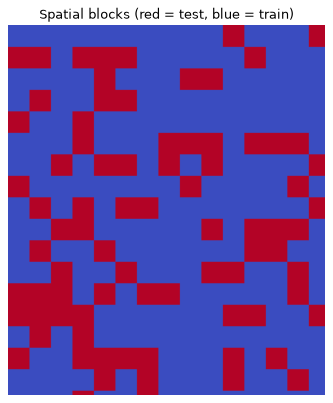

In [10]:
ny, nx = delta_NBR.shape
block = 50  # 50 px * 20 m = 1 km

yy, xx = np.meshgrid(np.arange(ny), np.arange(nx), indexing="ij")
block_id = ((yy // block) * ((nx // block) + 1) + (xx // block)).ravel()

rng = np.random.default_rng(RNG_SEED)
unique_blocks = np.unique(block_id)
test_blocks = rng.choice(unique_blocks, size=int(0.3 * len(unique_blocks)), replace=False)
is_test = np.isin(block_id, test_blocks)

labelled = label >= 0
train_idx = np.where(labelled & ~is_test)[0]
test_idx = np.where(labelled & is_test)[0]


# there are tens of thousands of pixels per class, so I subsample to keep training quick
# and balance the classes so the forest isn't biased towards unburnt
def balanced_sample(idx, n_per_class=15000):
    picks = []
    for c in (0, 1):
        cls = idx[label[idx] == c]
        picks.append(rng.choice(cls, size=min(n_per_class, len(cls)), replace=False))
    return np.concatenate(picks)


train_s = balanced_sample(train_idx)
print("train pixels:", len(train_s), "| test pixels (all labelled in test blocks):", len(test_idx))

# show where the train/test blocks are, so you can see it isn't random pixels
plt.figure(figsize=(6, 6))
plt.imshow(is_test.reshape(ny, nx), cmap="coolwarm")
plt.title("Spatial blocks (red = test, blue = train)")
plt.axis("off")
plt.show()

In [11]:
def train_rf(X, train_rows):
    # 200 trees is plenty here. min_samples_leaf=5 stops it memorising single noisy pixels
    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1,
                                random_state=RNG_SEED, class_weight="balanced")
    rf.fit(X[train_rows], label[train_rows])
    return rf


def evaluate(rf, X, rows, name):
    pred = rf.predict(X[rows])
    print(f"--- {name} (spatially held-out test blocks) ---")
    print(f"accuracy: {accuracy_score(label[rows], pred):.4f}   kappa: {cohen_kappa_score(label[rows], pred):.4f}")
    print(classification_report(label[rows], pred, target_names=["unburnt", "burnt"], digits=4))
    return pred


rf_A = train_rf(X_A, train_s)
rf_B = train_rf(X_B, train_s)
pred_A_test = evaluate(rf_A, X_A, test_idx, "Model A (pre + post)")
pred_B_test = evaluate(rf_B, X_B, test_idx, "Model B (post-fire only)")

--- Model A (pre + post) (spatially held-out test blocks) ---
accuracy: 1.0000   kappa: 1.0000
              precision    recall  f1-score   support

     unburnt     1.0000    1.0000    1.0000     76258
       burnt     1.0000    1.0000    1.0000     41279

    accuracy                         1.0000    117537
   macro avg     1.0000    1.0000    1.0000    117537
weighted avg     1.0000    1.0000    1.0000    117537



--- Model B (post-fire only) (spatially held-out test blocks) ---
accuracy: 0.9877   kappa: 0.9732
              precision    recall  f1-score   support

     unburnt     0.9940    0.9871    0.9905     76258
       burnt     0.9764    0.9890    0.9827     41279

    accuracy                         0.9877    117537
   macro avg     0.9852    0.9880    0.9866    117537
weighted avg     0.9878    0.9877    0.9878    117537



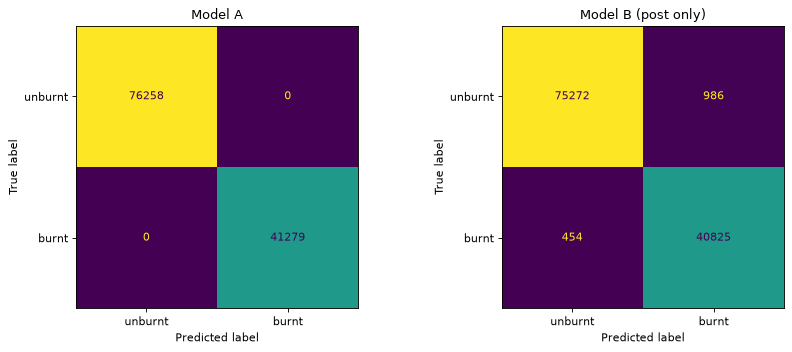

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, title in [(axes[0], pred_A_test, "Model A"), (axes[1], pred_B_test, "Model B (post only)")]:
    ConfusionMatrixDisplay(confusion_matrix(label[test_idx], pred),
                           display_labels=["unburnt", "burnt"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(title)
plt.tight_layout()
plt.show()

### What is the forest actually using?

The default `feature_importances_` from sklearn is known to be biased (it favours features with lots of distinct values), so I use **permutation importance** on the test set: shuffle one feature and see how much the accuracy drops.

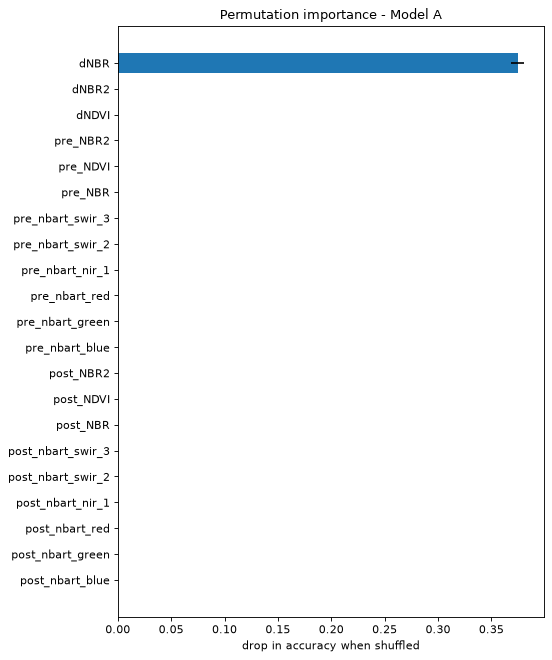

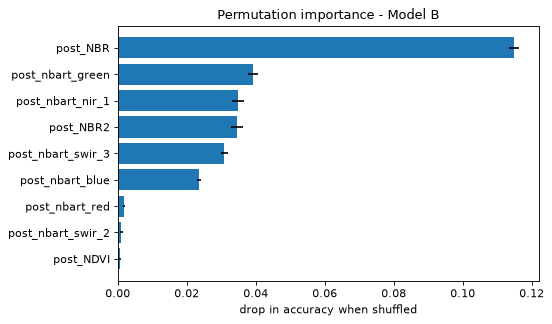

Top Model B features:
 post_NBR             0.1148
post_nbart_green     0.0392
post_nbart_nir_1     0.0348
post_NBR2            0.0346
post_nbart_swir_3    0.0309
dtype: float64


In [13]:
def plot_importance(rf, X, rows, names, title, n_rows=5000):
    sub = rng.choice(rows, size=min(n_rows, len(rows)), replace=False)
    r = permutation_importance(rf, X[sub], label[sub], n_repeats=5,
                               random_state=RNG_SEED, n_jobs=-1)
    order = np.argsort(r.importances_mean)
    plt.figure(figsize=(7, 0.35 * len(names) + 1))
    plt.barh(np.array(names)[order], r.importances_mean[order], xerr=r.importances_std[order])
    plt.title(title)
    plt.xlabel("drop in accuracy when shuffled")
    plt.tight_layout()
    plt.show()
    return pd.Series(r.importances_mean, index=names).sort_values(ascending=False)


imp_A = plot_importance(rf_A, X_A, test_idx, names_A, "Permutation importance - Model A")
imp_B = plot_importance(rf_B, X_B, test_idx, names_B, "Permutation importance - Model B")
print("Top Model B features:\n", imp_B.head(5).round(4))

Model A's importances will be dominated by dNBR because the labels came from it (that's the circularity from earlier). Model B's are more telling, since they show which single-date bands give a burn away.

## Mapping the whole area

Now I run both models over **every** pixel, including the uncertain 0.1-0.44 zone they never trained on, and compare with the threshold map.

In [14]:
def predict_map(rf, X, ok, shape):
    out = np.full(X.shape[0], np.nan)
    out[ok] = rf.predict(X[ok])
    return out.reshape(shape)


map_A = predict_map(rf_A, X_A, ok_A, (ny, nx))
map_B = predict_map(rf_B, X_B, ok_B, (ny, nx))
thr = np.where(valid.values, burnt_threshold.values.astype(float), np.nan)

summary = pd.DataFrame({
    "method": ["dNBR > 0.3 (DEA)", "RF Model A (pre+post)", "RF Model B (post only)"],
    "burnt km2": [np.nansum(thr) * pixel_km2, np.nansum(map_A) * pixel_km2, np.nansum(map_B) * pixel_km2],
})
# agreement with the threshold map over all valid land pixels
land = valid.values & (baseline_med.NDVI.values > 0)
summary["agreement with threshold"] = [1.0,
                                       np.mean(map_A[land] == thr[land]),
                                       np.mean(map_B[land] == thr[land])]
summary.round(3)

,method,burnt km2,agreement with threshold
0,dNBR > 0.3 (DEA),95.595,1.000
1,RF Model A (pre+post),103.100,0.968
2,RF Model B (post only),93.439,0.914


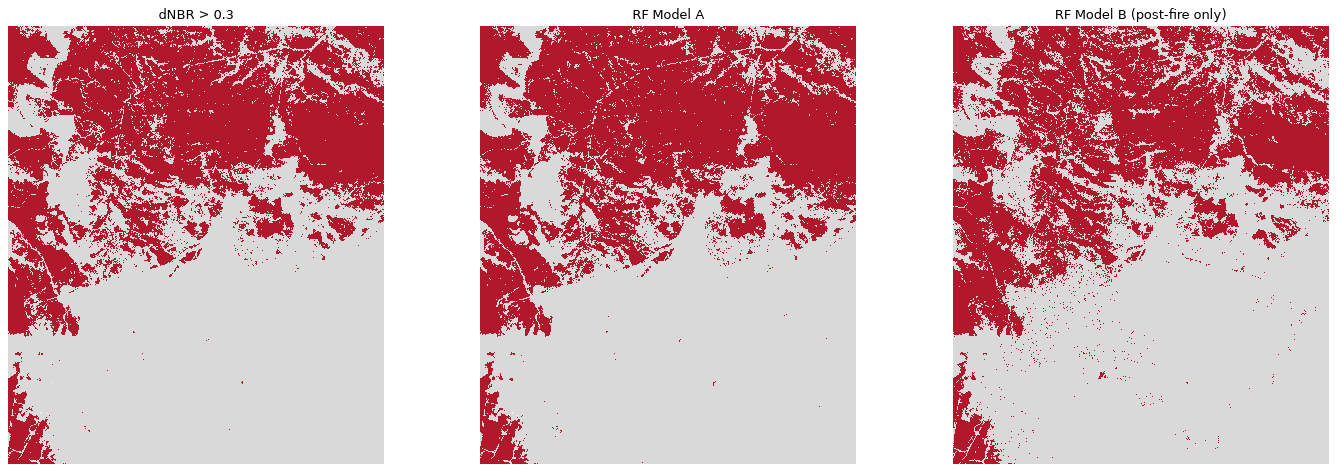

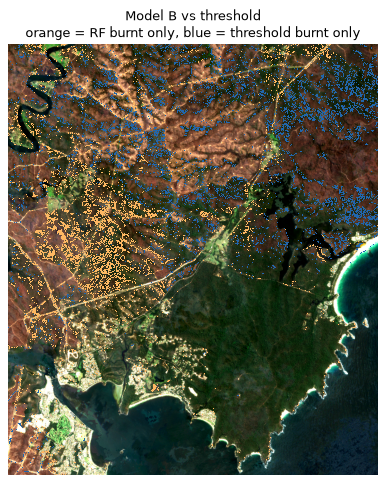

In [15]:
burn_cmap = ListedColormap(["#d9d9d9", "#b2182b"])  # grey unburnt, red burnt

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, m, t in [(axes[0], thr, "dNBR > 0.3"), (axes[1], map_A, "RF Model A"), (axes[2], map_B, "RF Model B (post-fire only)")]:
    ax.imshow(m, cmap=burn_cmap, vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(t)
    ax.axis("off")
plt.tight_layout()
plt.show()

# where does model B disagree with the threshold?
diff = np.full((ny, nx), np.nan)
diff[(map_B == 1) & (thr == 0)] = 1   # RF says burnt, threshold says no
diff[(map_B == 0) & (thr == 1)] = 0   # threshold says burnt, RF says no
plt.figure(figsize=(7, 7))
plt.imshow(rgb_array(post_med))
plt.imshow(diff, cmap=ListedColormap(["#2166ac", "#fdb863"]), vmin=0, vmax=1, interpolation="nearest")
plt.title("Model B vs threshold\norange = RF burnt only, blue = threshold burnt only")
plt.axis("off")
plt.show()

## Transfer test: Binna Burra / Sarabah fire, Queensland (Sept 2019)

Doing well on the same fire you trained on doesn't prove much. So here I run the **same trained models** on a different fire: the Sarabah fire in the Gold Coast hinterland, which burnt into Lamington National Park and destroyed the historic Binna Burra Lodge around 8 September 2019. It's also near the SE Queensland area I was looking at in notebook 01.

It's a hard test on purpose. It's a different state and season, with a mix of rainforest, wet sclerophyll and cleared farmland, versus the dry coastal forest at Batemans Bay. No labels from this fire are used for training. The only reference is the same dNBR > 0.3 rule.

In [16]:
# rough centre between Binna Burra and the Sarabah valley
qld_lat, qld_lon, qld_buf = -28.18, 153.15, 0.06
qld_bbox = [qld_lon - qld_buf, qld_lat - qld_buf, qld_lon + qld_buf, qld_lat + qld_buf]

# fire started ~6 Sep 2019. post window is short because more fires hit the region from Nov
qld_pre = load_s2_ard(qld_bbox, "2019-06-01/2019-09-04")
qld_post = load_s2_ard(qld_bbox, "2019-09-15/2019-10-31")

qld_pre_med = add_indices(qld_pre.median("time"))
qld_post_med = add_indices(qld_post.median("time"))
qld_dnbr = qld_pre_med.NBR - qld_post_med.NBR

2019-06-01/2019-09-04: 38 time steps found, keeping 24 with >= 80% good data


2019-09-15/2019-10-31: 17 time steps found, keeping 6 with >= 80% good data


burnt km2 - threshold: 13.59 | Model A: 18.42 | Model B: 14.72
agreement with threshold - Model A: 0.976 | Model B: 0.935


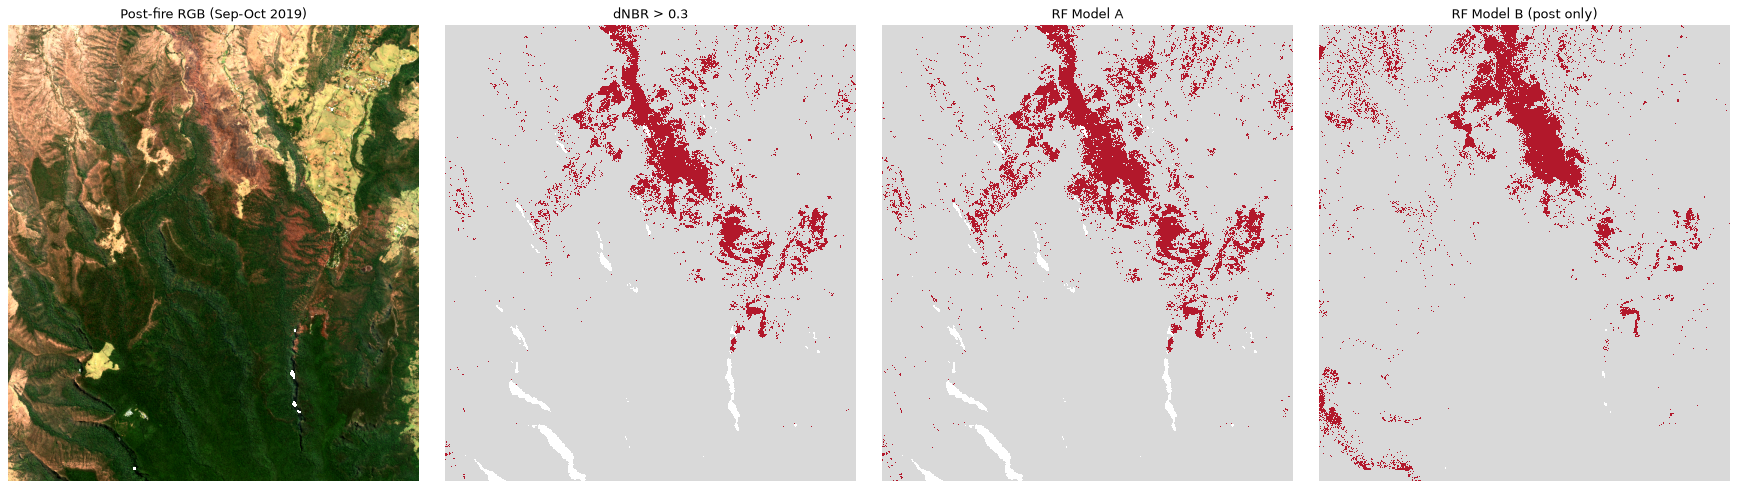

In [17]:
qy, qx = qld_dnbr.shape
qX_A, qok_A, _ = to_table(make_features(qld_pre_med, qld_post_med, include_pre=True))
qX_B, qok_B, _ = to_table(make_features(qld_pre_med, qld_post_med, include_pre=False))

q_thr = np.where(qld_dnbr.notnull().values, (qld_dnbr > 0.3).values.astype(float), np.nan)
q_A = predict_map(rf_A, qX_A, qok_A, (qy, qx))
q_B = predict_map(rf_B, qX_B, qok_B, (qy, qx))

q_land = qld_dnbr.notnull().values & (qld_pre_med.NDVI.values > 0)
print(f"burnt km2 - threshold: {np.nansum(q_thr)*pixel_km2:.2f} | "
      f"Model A: {np.nansum(q_A)*pixel_km2:.2f} | Model B: {np.nansum(q_B)*pixel_km2:.2f}")
print(f"agreement with threshold - Model A: {np.mean(q_A[q_land] == q_thr[q_land]):.3f} | "
      f"Model B: {np.mean(q_B[q_land] == q_thr[q_land]):.3f}")

fig, axes = plt.subplots(1, 4, figsize=(22, 6))
axes[0].imshow(rgb_array(qld_post_med)); axes[0].set_title("Post-fire RGB (Sep-Oct 2019)")
for ax, m, t in [(axes[1], q_thr, "dNBR > 0.3"), (axes[2], q_A, "RF Model A"), (axes[3], q_B, "RF Model B (post only)")]:
    ax.imshow(m, cmap=burn_cmap, vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(t)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Export

The same idea as the DEA notebook's `write_cog` step, done with rioxarray. The outputs go in `outputs/`, which is gitignored so the rasters don't get committed.

In [18]:
os.makedirs("outputs", exist_ok=True)

delta_NBR.rio.write_crs("EPSG:3577").rio.to_raster("outputs/clyde_mountain_dNBR.tif")

rf_map = xr.DataArray(map_B, coords=delta_NBR.coords, dims=delta_NBR.dims)
rf_map.rio.write_crs("EPSG:3577").rio.to_raster("outputs/clyde_mountain_rf_modelB_burnt.tif")
print("saved:", os.listdir("outputs"))

saved: ['clyde_mountain_dNBR.tif', 'clyde_mountain_rf_modelB_burnt.tif']


## What I found / notes to self

**Checking against DEA:** my loader kept 8/17 baseline and 8/18 post-fire time steps, which is exactly what the DEA notebook reports. Burnt area came out at **95.6 km2 vs DEA's 96.6 km2** (about 1% off, which I think is just the pixel grid being snapped a bit differently). So the Sandbox isn't needed for this.

**Model A (pre + post):** 100% on the held-out blocks. Like I said above, that isn't impressive, because dNBR is both an input and where the labels came from. Over the whole area it calls about 103 km2 burnt, more than the threshold, because it treats a lot of the 0.1-0.44 grey zone as burnt.

**Model B (post-fire only):** this is the result I actually care about.
- 98.8% accuracy (kappa 0.97) on the held-out blocks, from just one post-fire composite with no before image
- over the whole area it agrees with the dNBR map on about 91% of land pixels and gives 93.4 km2 burnt (threshold: 95.6)
- post-fire NBR was by far the most important feature, then green, NIR and NBR2

**Transfer to Binna Burra (QLD):** threshold 13.6 km2, Model A 18.4 km2, Model B 14.7 km2. Agreement with the threshold was 97.6% (A) and 93.5% (B). Model B finds the main Sarabah burn scar well, but it also flags some dry/bare hillside in the south-west corner that the dNBR map says didn't burn. That's the classic problem with post-fire-only mapping, where brown dry country looks burnt if you don't know what it looked like before. More training fires from QLD-type landscapes would probably fix a lot of it.

**Limitations**
- The labels are pseudo-labels from dNBR, so this measures "how well can it reproduce dNBR", not true burn accuracy.
- Only one training fire. A real model should be trained on many fires across different vegetation types.
- Smoke, harvesting and drought browning can all look like burns (the DEA notebook warns about this too).

**Next steps**
- Use the NSW Fire Extent and Severity Mapping (FESM) or QLD fire scar data as real labels
- Train on several Black Summer fires and test on fires it's never seen
- Predict severity classes, not just burnt/unburnt
- Bring the YOLOv7/Detectron2 work in: detect active fire from cameras/hotspots, then map the burn scar afterwards with this